In [114]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

In [116]:
#Data Collection 
titanic_data=pd.read_csv('Titanic-Dataset.csv')

In [117]:
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [118]:
titanic_data.shape

(891, 12)

In [119]:
#checking for missing values
titanic_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [120]:
# Handling the missing missing value
age_mean=titanic_data['Age'].mean()
print(age_mean)

29.69911764705882


In [121]:
titanic_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [122]:
titanic_data['Age'] = titanic_data['Age'].fillna(age_mean)

In [123]:
titanic_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [124]:
print(titanic_data['Embarked'].mode()[0])

S


In [125]:
#replacing the missing values in embarked colum with code
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(titanic_data['Embarked'].mode()[0])
#titanic_data = titanic_data.replace({'Sex': {'male': 1, 'female': 0}, 'Embarked': {'S': 0, 'C': 1, 'Q': 2}})

In [126]:
titanic_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [127]:
titanic_data=titanic_data.drop(columns='Cabin')

In [128]:
titanic_data.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [129]:
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [130]:
titanic_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [131]:
titanic_data['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [132]:
#Data visualization
sns.set()

<Axes: xlabel='Survived', ylabel='count'>

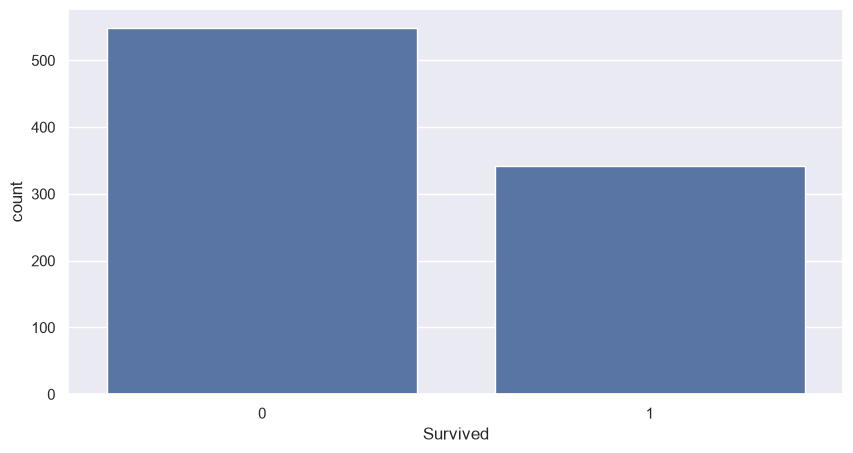

In [133]:
plt.figure(figsize=(10,5))
sns.countplot(x='Survived', data=titanic_data)

<Axes: xlabel='Sex', ylabel='count'>

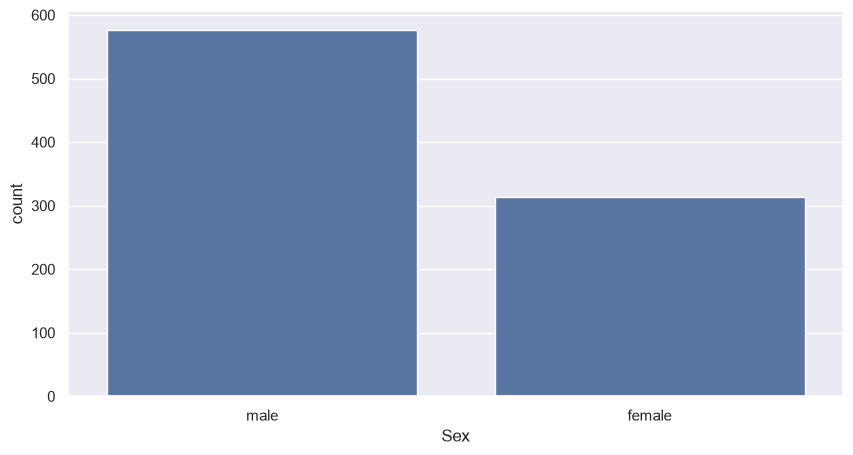

In [134]:
plt.figure(figsize=(10,5))
sns.countplot(x='Sex', data=titanic_data)

<Axes: xlabel='Sex', ylabel='count'>

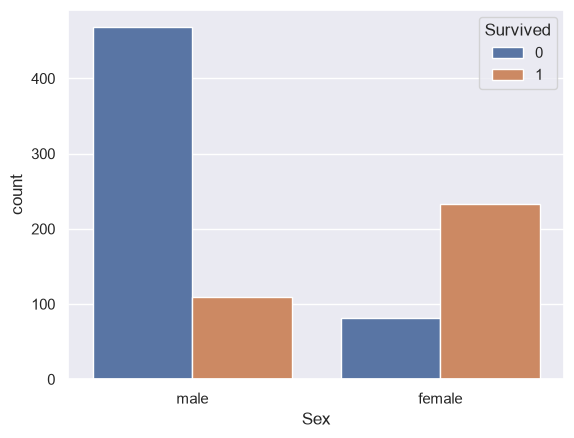

In [135]:
sns.countplot(x='Sex', hue='Survived', data=titanic_data)

<Axes: xlabel='Pclass', ylabel='count'>

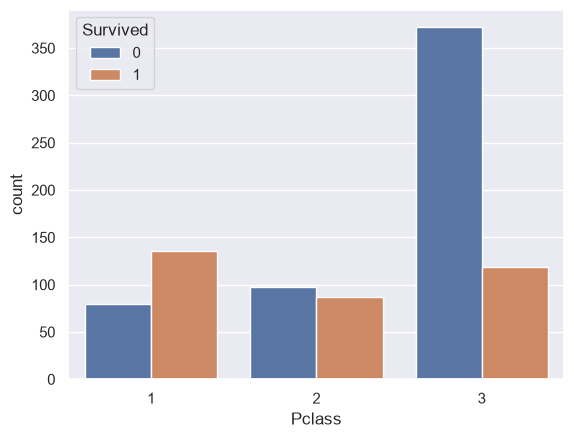

In [136]:
sns.countplot(x='Pclass', hue='Survived', data= titanic_data)

In [137]:
titanic_data['Embarked'].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [138]:
#titanic_data = titanic_data.replace({'Sex': {'male': 1, 'female': 0}, 'Embarked': {'S': 0, 'C': 1, 'Q': 2}})
titanic_data = titanic_data.replace({'Sex': {'male': 1, 'female': 0}})

In [139]:
titanic_data = pd.get_dummies(titanic_data, columns=['Embarked'], dtype=int)

In [140]:
titanic_data['FamilySize'] = titanic_data['SibSp'] + titanic_data['Parch'] + 1

In [141]:
titanic_data['IsAlone'] = (titanic_data['FamilySize'] == 1).astype(int)

In [142]:
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0,0,1,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1,0,0,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0,0,1,2,0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0,0,1,1,1


In [143]:
X = titanic_data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Survived'])
Y = titanic_data['Survived']

In [144]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize,IsAlone
0,3,1,22.0,1,0,7.2500,0,0,1,2,0
1,1,0,38.0,1,0,71.2833,1,0,0,2,0
2,3,0,26.0,0,0,7.9250,0,0,1,1,1
3,1,0,35.0,1,0,53.1000,0,0,1,2,0
4,3,1,35.0,0,0,8.0500,0,0,1,1,1


In [145]:
print(X)
print(Y)

     Pclass Sex        Age  SibSp  Parch     Fare  Embarked_C  Embarked_Q  \
0         3   1  22.000000      1      0   7.2500           0           0   
1         1   0  38.000000      1      0  71.2833           1           0   
2         3   0  26.000000      0      0   7.9250           0           0   
3         1   0  35.000000      1      0  53.1000           0           0   
4         3   1  35.000000      0      0   8.0500           0           0   
..      ...  ..        ...    ...    ...      ...         ...         ...   
886       2   1  27.000000      0      0  13.0000           0           0   
887       1   0  19.000000      0      0  30.0000           0           0   
888       3   0  29.699118      1      2  23.4500           0           0   
889       1   1  26.000000      0      0  30.0000           1           0   
890       3   1  32.000000      0      0   7.7500           0           1   

     Embarked_S  FamilySize  IsAlone  
0             1           2        0

In [146]:
#splitting the data into test and training data
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

In [147]:
print(X.shape, X_train.shape, X_test.shape)

(891, 11) (712, 11) (179, 11)


In [148]:
#model training
model=LogisticRegression()

In [149]:
model.fit(X_train, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [150]:
#accuracy score on trained data
X_train_prediction=model.predict(X_train)
training_data_accuracy = accuracy_score(Y_train,X_train_prediction)
print('accuracy score on trained data: ', training_data_accuracy)

accuracy score on trained data:  0.8117977528089888


In [153]:
#accuracy score on test data
X_test_prediction=model.predict(X_test)
test_data_accuracy = accuracy_score(Y_test,X_test_prediction)
print('accuracy score on test data: ', test_data_accuracy)

accuracy score on test data:  0.776536312849162


In [158]:
#Making predictive system
input_data = pd.DataFrame([[3, 0, 26.0, 0, 0, 7.925, 0, 0, 1, 1, 1]], columns=X.columns)
prediction = model.predict(input_data)
print(prediction)
if prediction[0] == 0:
    print('The person did not survive')
else:
    print('The person survived')

[1]
The person survived


In [159]:
from sklearn.metrics import confusion_matrix
confusion_matrix(Y_test, X_test_prediction)

array([[88, 12],
       [28, 51]])

In [162]:
chances = model.predict_proba(X_test)[:, 1]

threshold = 0.5
new_predictions = (chances >= threshold).astype(int)

print(confusion_matrix(Y_test, new_predictions))
print('Accuracy:', accuracy_score(Y_test, new_predictions))

[[88 12]
 [28 51]]
Accuracy: 0.776536312849162
